# Benchmark figures: RISoTTo vs gRNAde vs RhoDesign

Reproduces the following paper figures (written to `paper/figures/` as `.png`, `.svg` and `.pdf`):

| figure | metric | data |
|---|---|---|
| `recovery_boxplot_risotto_grnade_rhodesign` | sequence recovery | `data/recovery_sc_comparison_risotto_grnade_rhodesign.csv` |
| `sc_boxplot_risotto_grnade_rhodesign` | 2D self-consistency (EternaFold MCC) | `data/recovery_sc_comparison_risotto_grnade_rhodesign.csv` |
| `rmsd_boxplot_risotto_grnade_rhodesign` | C4' RMSD of the AF3-folded design to the native structure | `data/rmsd_gddt_tm_comparison_risotto_grnade_rhodesign.csv` |
| `plddt_boxplot_risotto_grnade_rhodesign` | mean AF3 pLDDT of the designed chain | `data/rmsd_gddt_tm_comparison_risotto_grnade_rhodesign.csv` |

Each box plot only uses the targets that have a value for **all three methods**.

By default the figures are drawn from the metric tables committed in `paper/data/`. Set `RECOMPUTE = True` to rebuild these tables from the raw data first (native structures, designs and AF3 predictions; see `paper/README.md` for the download and the EternaFold install).

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PAPER_DIR = os.path.abspath("")
REPO_DIR = os.path.dirname(PAPER_DIR)
DATA_DIR = os.path.join(PAPER_DIR, "data")
RAW_DIR = os.path.join(PAPER_DIR, "raw")
FIG_DIR = os.path.join(PAPER_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

RECOVERY_SC_CSV = os.path.join(DATA_DIR, "recovery_sc_comparison_risotto_grnade_rhodesign.csv")
STRUCTURE_CSV = os.path.join(DATA_DIR, "rmsd_gddt_tm_comparison_risotto_grnade_rhodesign.csv")

# rebuild the metric tables from paper/raw/ (slow, needs EternaFold)
RECOMPUTE = False

# method order and colours (RISoTTo in red)
METHODS = ["RISoTTo", "gRNAde", "RhoDesign"]
PREFS = ["risotto", "grnade", "rhodesign"]
COLORS = {"RISoTTo": "#C0392B", "gRNAde": "#E69F00", "RhoDesign": "#9B59B6"}

## 1. Metric tables (optional recompute)

Sources of the designed sequences:
- **RISoTTo**: `predictions/{PDBID}.fasta` (recovery is in the FASTA header).
- **gRNAde**: recovery and 2D self-consistency precomputed by gRNAde (`data/grnade_full_benchmark.csv`).
- **RhoDesign**: designed sequence read from its AF3 input JSON; recovery is the positional identity against the native chain.

2D self-consistency is the MCC between the EternaFold prediction of the designed sequence and the native dot-bracket.

3D metrics compare the C4' atoms of the AF3 top-ranked model of each designed chain with the native chain after optimal superposition. pLDDT is the per-chain mean of AF3 `atom_plddts`. Only chains folded for all three methods are kept.

In [2]:
if RECOMPUTE:
    from glob import glob
    sys.path.insert(0, REPO_DIR)
    import benchmark_lib as bl

    PDB_DIR = os.path.join(RAW_DIR, "native_pdbs")
    ETERNAFOLD = {
        "eternafold_path": os.path.join(REPO_DIR, "software/EternaFold/src/contrafold"),
        "params_path": os.path.join(REPO_DIR, "software/EternaFold/parameters/EternaFoldParams.v1"),
    }
    assert os.path.isdir(PDB_DIR), "raw data missing, see paper/README.md"
    assert os.path.exists(ETERNAFOLD["eternafold_path"]), "EternaFold not built, see paper/README.md"

    # sequence recovery and 2D self-consistency
    df = pd.read_csv(os.path.join(DATA_DIR, "grnade_full_benchmark.csv"))
    df["gRNAde_recovery"] = df["grnade_recovery"]
    df["gRNAde_sc_score"] = df["grnade_sc_score"]
    pdb_ids = df["pdb_id"].tolist()
    risotto_rec, risotto_sc = bl.collect(
        pdb_ids, os.path.join(REPO_DIR, "predictions", "{pdb_id}.fasta"), PDB_DIR,
        bl.evaluate_fasta_method, ETERNAFOLD, desc="RISoTTo")
    rho_rec, rho_sc = bl.collect(
        pdb_ids, os.path.join(RAW_DIR, "af3_inputs", "rhodesign", "{pdb_id}.json"), PDB_DIR,
        bl.evaluate_afjson_method, ETERNAFOLD, desc="RhoDesign")
    df["RISoTTo_recovery"] = df["pdb_id"].map(risotto_rec)
    df["RISoTTo_sc_score"] = df["pdb_id"].map(risotto_sc)
    df["RhoDesign_recovery"] = df["pdb_id"].map(rho_rec)
    df["RhoDesign_sc_score"] = df["pdb_id"].map(rho_sc)
    df = df[["pdb_id"] + [f"{m}_recovery" for m in METHODS] + [f"{m}_sc_score" for m in METHODS]]
    df.to_csv(RECOVERY_SC_CSV, index=False)

    # 3D structure recovery of the AF3-folded designs and pLDDT
    results = {
        pref: bl.process_designs(sorted(glob(os.path.join(RAW_DIR, "af3", pref, "pdbs", "*_model.pdb"))),
                                 PDB_DIR, desc=f"{pref} 3D")
        for pref in PREFS
    }
    common_keys = set.intersection(*[set(results[pref]) for pref in PREFS])
    rows = []
    for key in sorted(common_keys):
        entry = {"pdb_id": key}
        for pref in PREFS:
            entry[f"{pref}_rmsd"], entry[f"{pref}_gddt"], entry[f"{pref}_tm"] = results[pref][key]
        rows.append(entry)
    df_wide = pd.DataFrame(rows)
    for pref in PREFS:
        df_wide[f"{pref}_plddt"] = df_wide["pdb_id"].map(
            bl.plddt_map(os.path.join(RAW_DIR, "af3", pref, "confidences")))
    df_wide.to_csv(STRUCTURE_CSV, index=False)

In [3]:
recovery_sc_df = pd.read_csv(RECOVERY_SC_CSV)
structure_df = pd.read_csv(STRUCTURE_CSV)
for m in METHODS:
    print(f"{m:10s}: {recovery_sc_df[f'{m}_recovery'].notna().sum():4d} targets with recovery")
print(f"AF3-folded chains common to all methods: {len(structure_df)}")

RISoTTo   :  172 targets with recovery
gRNAde    :  172 targets with recovery
RhoDesign :   97 targets with recovery
AF3-folded chains common to all methods: 74


## 2. Figures

In [4]:
sns.set_style("white")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
    "font.weight": "bold",
    "axes.linewidth": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


def boxplot_metric(df, cols, ylabel, ylim, fig_name, fmt=None, figsize=(4.0, 3.8)):
    """Box plot (+ points) of one metric per method over the targets common to all methods.
    If `fmt` is given, the median of each method is written above its median line."""
    sub = df.dropna(subset=cols, how="any")
    print(f"n = {len(sub)} targets (common to all methods)")
    plot_df = pd.DataFrame([
        {"method": m, "value": float(v)} for c, m in zip(cols, METHODS) for v in sub[c].values
    ])

    # fixed seed for the strip-plot jitter
    np.random.seed(0)
    fig, ax = plt.subplots(figsize=figsize)
    sns.boxplot(data=plot_df, x="method", y="value", order=METHODS, hue="method",
                palette=COLORS, showfliers=False, width=0.6, linewidth=1.0,
                legend=False, ax=ax)
    sns.stripplot(data=plot_df, x="method", y="value", order=METHODS,
                  color="black", alpha=0.45, size=2.2, jitter=0.05, ax=ax)
    if fmt is not None:
        for i, c in enumerate(cols):
            m = float(np.median(sub[c].values))
            ax.text(i, m, fmt.format(m), color="black", fontsize=8, fontweight="bold",
                    ha="center", va="bottom")

    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=12, fontweight="bold")
    sns.despine(ax=ax)
    ax.tick_params(axis="y", which="major", direction="out", length=4, width=1.0)
    ax.yaxis.set_ticks_position("left")
    ax.set_axisbelow(True)
    ax.set_ylim(ylim)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, fig_name)
    plt.savefig(fig_path + ".svg")
    plt.savefig(fig_path + ".png", dpi=300)
    plt.savefig(fig_path + ".pdf", dpi=300)
    plt.show()

    # median +/- standard deviation
    for c, m in zip(cols, METHODS):
        print(f"{m:10s}: median = {sub[c].median():.3f} +/- {sub[c].std():.3f}")

### 2.1 Sequence recovery

n = 97 targets (common to all methods)


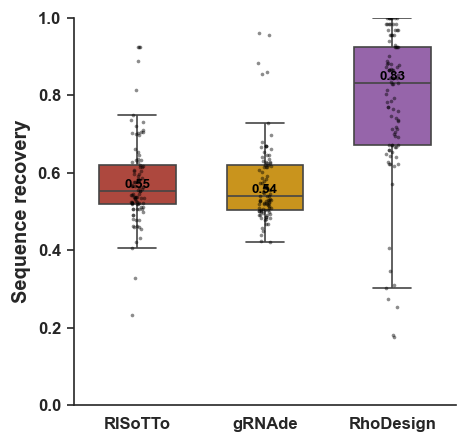

RISoTTo   : median = 0.552 +/- 0.113
gRNAde    : median = 0.540 +/- 0.102
RhoDesign : median = 0.831 +/- 0.194


In [5]:
boxplot_metric(recovery_sc_df, [f"{m}_recovery" for m in METHODS], "Sequence recovery",
               ylim=(0.0, 1.0), fmt="{:.2f}", fig_name="recovery_boxplot_risotto_grnade_rhodesign")

### 2.2 2D secondary-structure self-consistency

n = 95 targets (common to all methods)


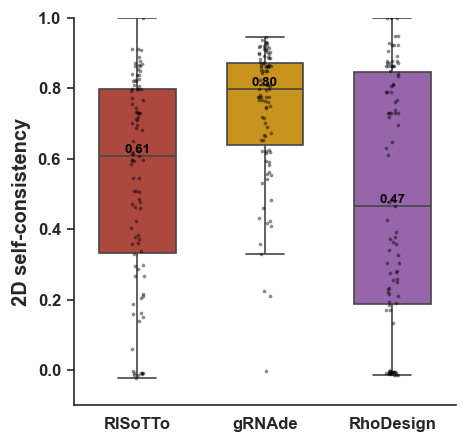

RISoTTo   : median = 0.609 +/- 0.290
gRNAde    : median = 0.797 +/- 0.187
RhoDesign : median = 0.467 +/- 0.358


In [6]:
boxplot_metric(recovery_sc_df, [f"{m}_sc_score" for m in METHODS], "2D self-consistency",
               ylim=(-0.1, 1.0), fmt="{:.2f}", fig_name="sc_boxplot_risotto_grnade_rhodesign")

### 2.3 AF3 RMSD to the native structure

n = 74 targets (common to all methods)


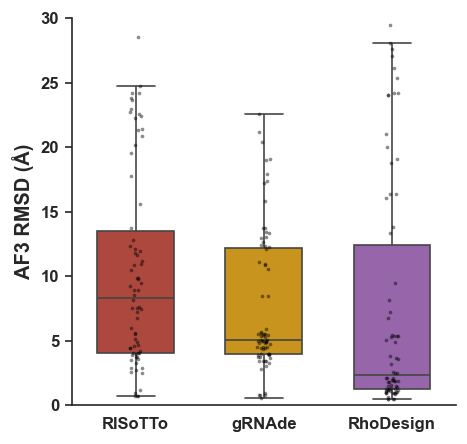

RISoTTo   : median = 8.348 +/- 7.592
gRNAde    : median = 5.075 +/- 5.517
RhoDesign : median = 2.332 +/- 9.045


In [7]:
boxplot_metric(structure_df, [f"{p}_rmsd" for p in PREFS], "AF3 RMSD (Å)",
               ylim=(0, 30), fig_name="rmsd_boxplot_risotto_grnade_rhodesign")

### 2.4 AF3 pLDDT

n = 74 targets (common to all methods)


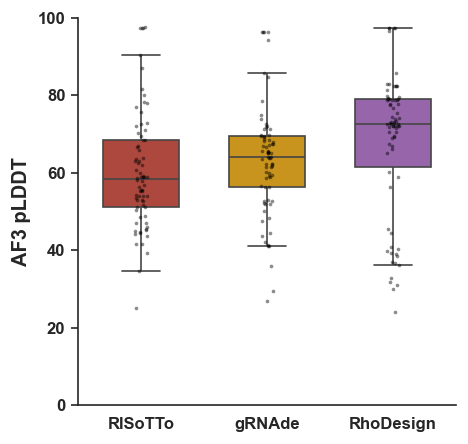

RISoTTo   : median = 58.433 +/- 15.077
gRNAde    : median = 64.031 +/- 14.329
RhoDesign : median = 72.620 +/- 18.329


In [8]:
boxplot_metric(structure_df, [f"{p}_plddt" for p in PREFS], "AF3 pLDDT",
               ylim=(0, 100), fig_name="plddt_boxplot_risotto_grnade_rhodesign")

### 2.5 Summary of 3D metrics (GDT_TS and TM-score, not plotted)

In [9]:
summary = pd.DataFrame({
    m: {f"{metric} {stat}": getattr(structure_df[f"{p}_{metric}"], stat)()
        for metric in ["rmsd", "gddt", "tm", "plddt"] for stat in ["median", "mean", "std"]}
    for m, p in zip(METHODS, PREFS)
})
summary.round(3)

,RISoTTo,gRNAde,RhoDesign
rmsd median,8.348,5.075,2.332
rmsd mean,10.282,7.720,7.475
rmsd std,7.592,5.517,9.045
gddt median,0.258,0.367,0.642
gddt mean,0.308,0.350,0.540
gddt std,0.263,0.246,0.360
tm median,0.214,0.326,0.699
tm mean,0.265,0.302,0.505
tm std,0.220,0.212,0.362
plddt median,58.433,64.031,72.620
